In [116]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [117]:
# Read dataset and convert to UTC datetime
df = pd.read_csv("/content/FR.csv")
df["datetime"] = pd.to_datetime(df["datetime"], utc=True)
df = df.sort_values("datetime").reset_index(drop=True)

# Find the longest continuous hourly segment (stops before the 8-day missing gap)
continuous_segment = (df["datetime"].diff() != pd.Timedelta(hours=1)).cumsum()
longest_id = continuous_segment.value_counts().idxmax()
clean_df = df[continuous_segment == longest_id].copy()

# Set hourly frequency index
forecast_series = clean_df.set_index("datetime")["carbonIntensity"].astype(float).asfreq("h")

print(f"Clean continuous hours: {len(forecast_series)}")
print(f"Date range: {forecast_series.index.min()} to {forecast_series.index.max()}")

Clean continuous hours: 2993
Date range: 2024-06-14 13:00:00+00:00 to 2024-10-17 05:00:00+00:00


<Axes: xlabel='datetime'>

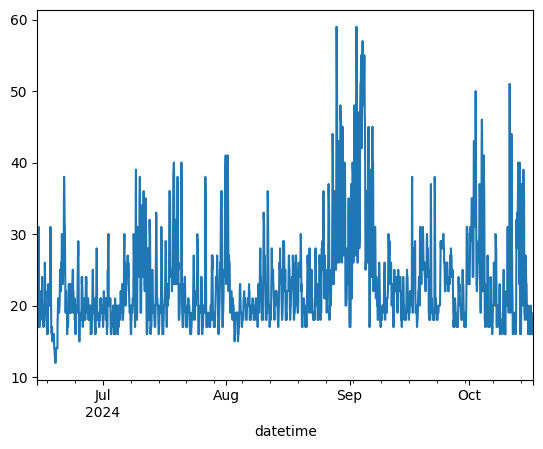

In [118]:
forecast_series.plot()

In [119]:
forecast_series.size

2993

In [120]:
forecast_series.describe()

,carbonIntensity
count,2993.000000
mean,23.068827
std,6.750020
min,12.000000
25%,19.000000
50%,21.000000
75%,25.000000
max,59.000000


In [121]:
df_base=pd.concat([forecast_series,forecast_series.shift(1)],axis=1)
df_base.head()

,carbonIntensity,carbonIntensity
datetime,,
2024-06-14 13:00:00+00:00,18.0,NaN
2024-06-14 14:00:00+00:00,18.0,18.0
2024-06-14 15:00:00+00:00,17.0,18.0
2024-06-14 16:00:00+00:00,17.0,17.0
2024-06-14 17:00:00+00:00,18.0,17.0


In [122]:
df_base.columns=["Actual_carbonintensity","Forecast_carbonintensity"]
df_base.head()

,Actual_carbonintensity,Forecast_carbonintensity
datetime,,
2024-06-14 13:00:00+00:00,18.0,NaN
2024-06-14 14:00:00+00:00,18.0,18.0
2024-06-14 15:00:00+00:00,17.0,18.0
2024-06-14 16:00:00+00:00,17.0,17.0
2024-06-14 17:00:00+00:00,18.0,17.0


In [123]:
df_base.dropna(inplace=True)
df_base.head()

,Actual_carbonintensity,Forecast_carbonintensity
datetime,,
2024-06-14 14:00:00+00:00,18.0,18.0
2024-06-14 15:00:00+00:00,17.0,18.0
2024-06-14 16:00:00+00:00,17.0,17.0
2024-06-14 17:00:00+00:00,18.0,17.0
2024-06-14 18:00:00+00:00,19.0,18.0


In [124]:
from sklearn.metrics import mean_absolute_error
import numpy as np

df_error = mean_absolute_error(df_base.Actual_carbonintensity, df_base.Forecast_carbonintensity)
print(f"Mean Absolute Error: {df_error}")

Mean Absolute Error: 1.400735294117647


In [125]:
from sklearn.metrics import mean_squared_error
import numpy as np

# Calculate Mean Squared Error first
mse = mean_squared_error(df_base.Actual_carbonintensity, df_base.Forecast_carbonintensity)

# Calculate Root Mean Squared Error (RMSE)
rmse = np.sqrt(mse)
print(f"Root Mean Squared Error (RMSE): {rmse}")

Root Mean Squared Error (RMSE): 2.5120697944934607


### ARIMA Forecasting Model

First, we will import the necessary statsmodels module and perform an Augmented Dickey-Fuller (ADF) test to evaluate if our series is stationary.

In [126]:
from statsmodels.tsa.stattools import adfuller

# Run the Augmented Dickey-Fuller test
print("Running Augmented Dickey-Fuller test...")
adf_result = adfuller(forecast_series)

print(f"ADF Statistic: {adf_result[0]:.4f}")
print(f"p-value: {adf_result[1]:.4e}")
print("Critical Values:")
for key, value in adf_result[4].items():
    print(f"   {key}: {value:.4f}")

Running Augmented Dickey-Fuller test...
ADF Statistic: -4.9132
p-value: 3.2864e-05
Critical Values:
   1%: -3.4326
   5%: -2.8625
   10%: -2.5673


/tmp/ipykernel_4172/2907861086.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(forecast_series)


Now, we will fit an ARIMA model. Since hourly carbon intensity exhibits strong temporal dependencies, we will initially fit a baseline configuration such as `ARIMA(1, 1, 1)` and review its summary.

In [127]:
from statsmodels.tsa.arima.model import ARIMA

# Define the ARIMA order (p, d, q)
# We'll use (1, 1, 1) as a starting baseline configuration
order = (1, 1, 1)

# Fit the ARIMA model
model = ARIMA(forecast_series, order=order)
model_fit = model.fit()

# Display model diagnostics and summary
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:        carbonIntensity   No. Observations:                 2993
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -6669.123
Date:                Mon, 19 Oct 2026   AIC                          13344.247
Time:                        17:34:12   BIC                          13362.258
Sample:                    06-14-2024   HQIC                         13350.726
                         - 10-17-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2096      0.025      8.315      0.000       0.160       0.259
ma.L1          0.2780      0.026     10.754      0.000       0.227       0.329
sigma2         5.0531      0.060     84.163      0.0

### Evaluating ARIMA Model on a Train-Test Split
We will train the ARIMA model on 80% of the data and forecast the remaining 20% to compare its performance against the baseline persistence model.

In [128]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Create features: 1 hour ago (lag_1) and 24 hours ago (lag_24)
model_data = pd.DataFrame({
    "actual": forecast_series,
    "lag_1": forecast_series.shift(1),
    "lag_24": forecast_series.shift(24)
}).dropna()

# 80/20 train/test split
train_size = int(len(model_data) * 0.8)
train_df = model_data.iloc[:train_size]
test_df = model_data.iloc[train_size:]

X_train, y_train = train_df[["lag_1", "lag_24"]], train_df["actual"]
X_test, y_test = test_df[["lag_1", "lag_24"]], test_df["actual"]

# Fit model and predict across the entire test set
model = LinearRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)

# Calculate metrics
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print(f"Test Set Hours Evaluated: {len(test_df)}")
print(f"Mean Absolute Error (MAE): {mae:.2f} gCO2eq/kWh")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} gCO2eq/kWh")

Test Set Hours Evaluated: 594
Mean Absolute Error (MAE): 1.65 gCO2eq/kWh
Root Mean Squared Error (RMSE): 2.81 gCO2eq/kWh


### 1-Step-Ahead Rolling Forecast with ARIMA
We will update the model with the actual observed value at each step to make a true 1-step-ahead forecast on the test set.

In [129]:
# Keep track of history and predictions
history = list(train)
rolling_predictions = []

print("Running rolling 1-step-ahead validation (this may take a minute)...")
# Perform 1-step-ahead rolling forecasting on the first 50 elements of the test set for efficiency
test_subset = test[:50]
for t in range(len(test_subset)):
    model_rolling = ARIMA(history, order=(1, 1, 1))
    model_rolling_fit = model_rolling.fit()
    output = model_rolling_fit.forecast()
    yhat = output[0]
    rolling_predictions.append(yhat)
    history.append(test_subset.iloc[t])

# Calculate metrics for 1-step-ahead forecasts
rolling_mae = mean_absolute_error(test_subset, rolling_predictions)
rolling_rmse = np.sqrt(mean_squared_error(test_subset, rolling_predictions))

print(f"--- ARIMA(1,1,1) 1-Step Rolling Evaluation (Subset) ---")
print(f"Mean Absolute Error (MAE): {rolling_mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rolling_rmse:.4f}")

Running rolling 1-step-ahead validation (this may take a minute)...
--- ARIMA(1,1,1) 1-Step Rolling Evaluation (Subset) ---
Mean Absolute Error (MAE): 2.6177
Root Mean Squared Error (RMSE): 4.1945


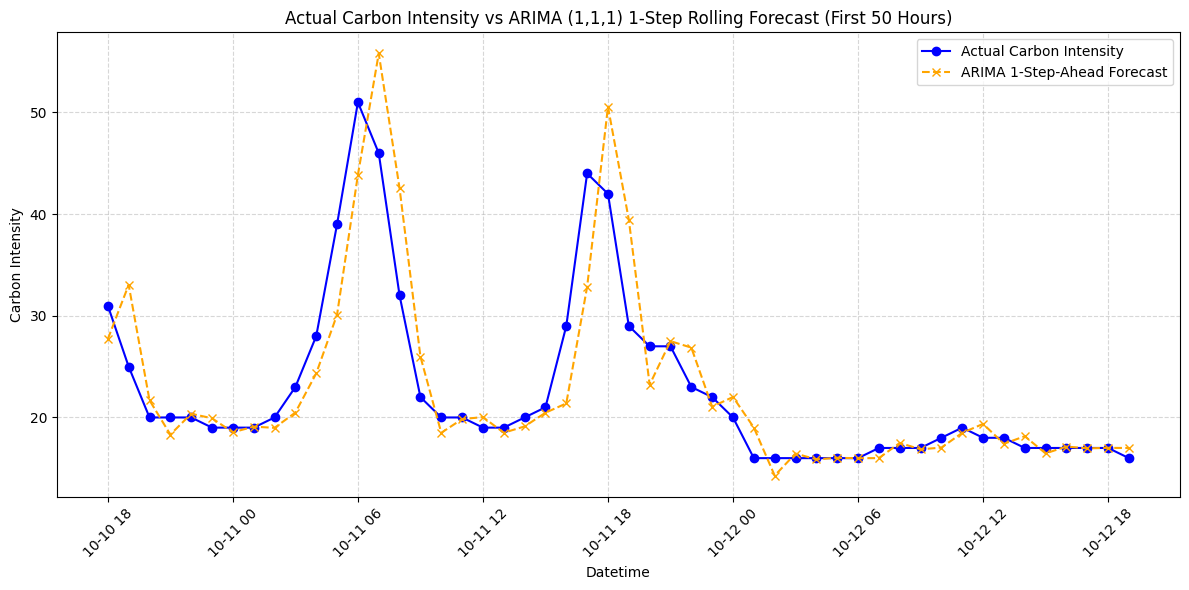

In [130]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(test_subset.index, test_subset.values, label='Actual Carbon Intensity', color='blue', marker='o')
plt.plot(test_subset.index, rolling_predictions, label='ARIMA 1-Step-Ahead Forecast', color='orange', linestyle='--', marker='x')

plt.title('Actual Carbon Intensity vs ARIMA (1,1,1) 1-Step Rolling Forecast (First 50 Hours)')
plt.xlabel('Datetime')
plt.ylabel('Carbon Intensity')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [131]:
# Save forecasts to CSV for merging with MIT workload traces later
output_df = pd.DataFrame({
    "datetime": y_test.index,
    "actual_intensity": y_test.values,
    "forecast_intensity": predictions
})

output_df.to_csv("/content/carbon_forecast.csv", index=False)
print("Successfully generated /content/carbon_forecast.csv!")
display(output_df.head())

Successfully generated /content/carbon_forecast.csv!


,datetime,actual_intensity,forecast_intensity
0,2024-09-22 12:00:00+00:00,30.0,35.408936
1,2024-09-22 13:00:00+00:00,22.0,29.249165
2,2024-09-22 14:00:00+00:00,21.0,21.932596
3,2024-09-22 15:00:00+00:00,19.0,20.856164
4,2024-09-22 16:00:00+00:00,20.0,19.101726


In [132]:
from google.colab import files
files.download("/content/carbon_forecast.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>